Total de genes no painel de sequenciamento: 538
Total de variantes brutas carregadas: 4069
Total de pacientes pareados (Normal -> AK -> cSCC): 16

ARID2 presente no painel? True
Genes da via MAPK validados no painel (21): ['ARAF', 'BRAF', 'EGFR', 'HRAS', 'KRAS', 'MAP2K1', 'MAP2K2', 'MAP2K4', 'MAP3K1', 'MAP3K2', 'MAP3K5', 'MAP3K7', 'MAP3K9', 'MAPK1', 'MAPK8IP1', 'MRAS', 'NRAS', 'RAF1', 'RASA1', 'RRAS', 'RRAS2']

Variantes funcionais identificadas no eixo ARID2–MAPK: 37

TABELA 1: ESTATÍSTICA DESCRITIVA DA FRAÇÃO ALÉLICA MUTANTE (MAF)
                Normal_MAF                                AK_MAF          \
                     count    mean     std  median    IQR  count    mean   
Grupo_Biologico                                                            
ARID2                    8  0.0019  0.0053  0.0000  0.000      8  0.0269   
Via MAPK                29  0.0173  0.0312  0.0018  0.026     29  0.0678   

                                        SCC_MAF                          \
     

/tmp/ipykernel_4968/1016254469.py:136: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:black'` for the same effect.

  sns.stripplot(


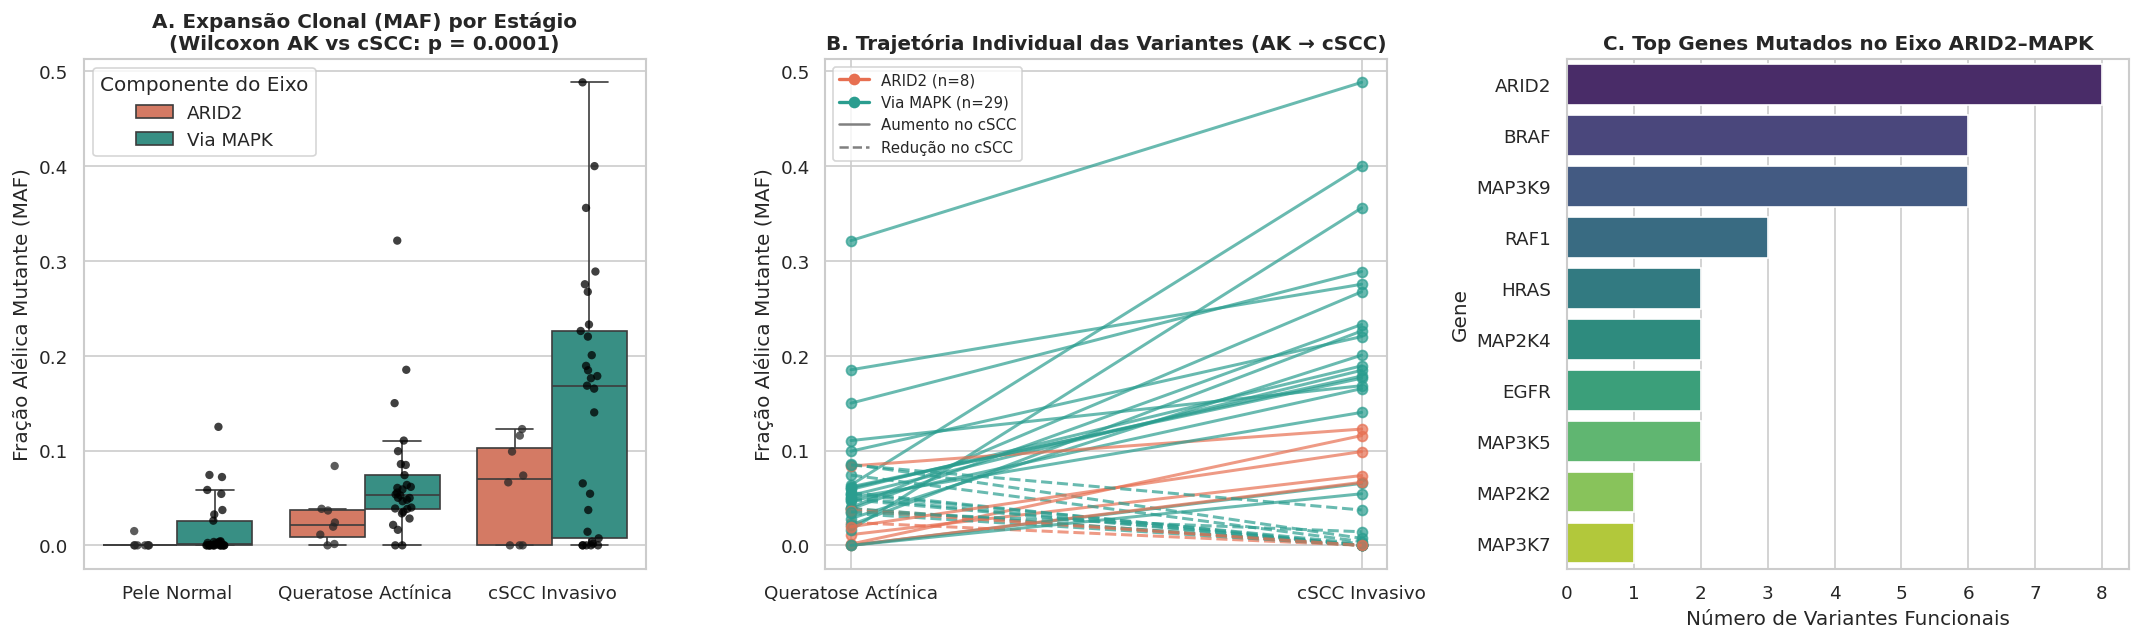

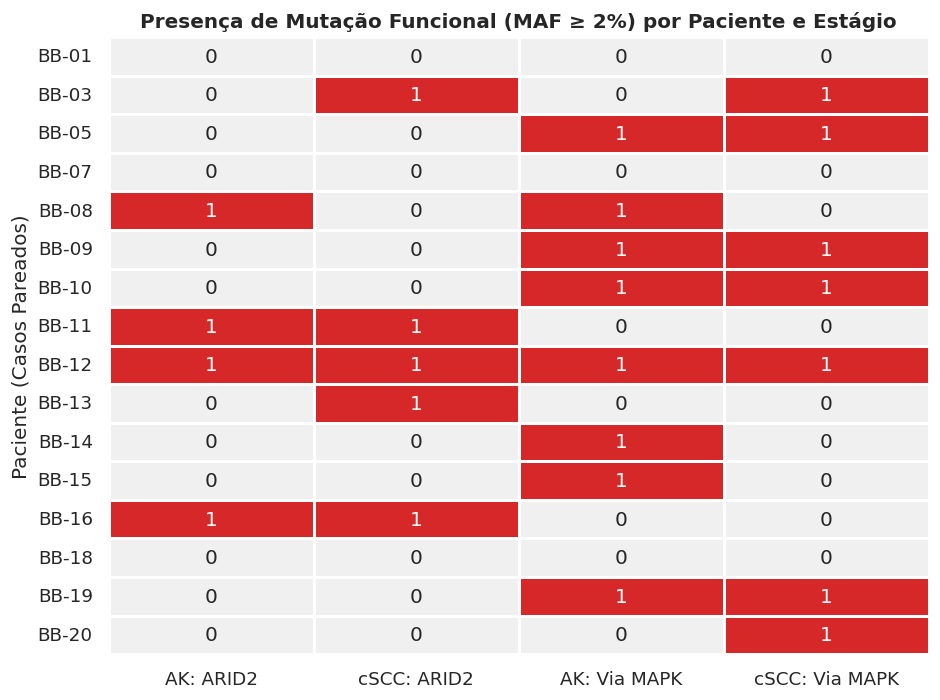

In [ ]:
# ==============================================================================
# PROJETO: Eixo ARID2–MAPK na Progressão de Queratose Actínica (AK) para cSCC
# AMBIENTE: Google Colab (Pré-processamento, Estatística Descritiva e Testes)
# ==============================================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Configuração visual dos gráficos para padrão de publicação científica
sns.set_theme(style="whitegrid", context="notebook", palette="Set2")
plt.rcParams['figure.dpi'] = 120

# ------------------------------------------------------------------------------
# 1. LEITURA E PRÉ-PROCESSAMENTO DOS DADOS (Download direto dos links oficiais)
# ------------------------------------------------------------------------------
# URLs de download dos materiais suplementares (MOESM8 e MOESM9)
arquivo_painel = 'https://static-content.springer.com/esm/art%3A10.1038%2Fs41467-025-65687-y/MediaObjects/41467_2025_65687_MOESM8_ESM.xlsx'
arquivo_mutacoes = 'https://static-content.springer.com/esm/art%3A10.1038%2Fs41467-025-65687-y/MediaObjects/41467_2025_65687_MOESM9_ESM.xlsx'

# Note o parâmetro 'header': as planilhas possuem títulos nas primeiras linhas,
# então indicamos exatamente em qual linha começa o cabeçalho real (índice 0-based).
df_painel = pd.read_excel(arquivo_painel, sheet_name='v.3.0TargetGenes', header=2)
df_mut = pd.read_excel(arquivo_mutacoes, sheet_name='TableS5', header=1)

# Limpeza básica: remover linhas totalmente vazias, se houver
df_painel.dropna(subset=['Gene'], inplace=True)
df_mut.dropna(subset=['Case', 'Hugo_Symbol'], inplace=True)

print(f"Total de genes no painel de sequenciamento: {df_painel['Gene'].nunique()}")
print(f"Total de variantes brutas carregadas: {len(df_mut)}")
print(f"Total de pacientes pareados (Normal -> AK -> cSCC): {df_mut['Case'].nunique()}")

# ------------------------------------------------------------------------------
# 2. DEFINIÇÃO DO EIXO ARID2–MAPK E FILTRAGEM FUNCIONAL
# ------------------------------------------------------------------------------
# Genes clássicos da via RTK-RAS-RAF-MEK-ERK (MAPK) presentes na literatura oncológica
genes_mapk_candidatos = [
    'EGFR', 'HRAS', 'KRAS', 'NRAS', 'MRAS', 'RRAS', 'RRAS2', 'RASA1',
    'ARAF', 'BRAF', 'RAF1', 'MAP2K1', 'MAP2K2', 'MAP2K4',
    'MAP3K1', 'MAP3K2', 'MAP3K5', 'MAP3K7', 'MAP3K9', 'MAPK1', 'MAPK8IP1'
]

# Validação cruzada: quais desses genes realmente estavam no painel capturado?
genes_sequenciados = set(df_painel['Gene'].unique())
genes_mapk_painel = sorted([g for g in genes_mapk_candidatos if g in genes_sequenciados])
arid2_no_painel = 'ARID2' in genes_sequenciados

print(f"\nARID2 presente no painel? {arid2_no_painel}")
print(f"Genes da via MAPK validados no painel ({len(genes_mapk_painel)}): {genes_mapk_painel}")

# Classificar cada variante quanto ao grupo biológico
def classificar_eixo(gene):
    if gene == 'ARID2':
        return 'ARID2'
    elif gene in genes_mapk_painel:
        return 'Via MAPK'
    else:
        return 'Outros Genes'

df_mut['Grupo_Biologico'] = df_mut['Hugo_Symbol'].apply(classificar_eixo)

# Filtrar apenas mutações com potencial impacto proteico/funcional (não-sinônimas)
classes_funcionais = [
    'Missense_Mutation', 'Nonsense_Mutation', 'Frame_Shift_Del', 'Frame_Shift_Ins',
    'Splice_Site', 'In_Frame_Del', 'Start_Codon_SNP', 'De_novo_Start_InFrame'
]
df_mut['Mutacao_Funcional'] = df_mut['Variant_Classification'].isin(classes_funcionais)

# Dataset focado apenas nas variantes funcionais do eixo ARID2–MAPK
df_eixo = df_mut[
    (df_mut['Grupo_Biologico'].isin(['ARID2', 'Via MAPK'])) &
    (df_mut['Mutacao_Funcional'])
].copy()

print(f"\nVariantes funcionais identificadas no eixo ARID2–MAPK: {len(df_eixo)}")

# ------------------------------------------------------------------------------
# 3. TABELAS DESCRITIVAS E TESTES ESTATÍSTICOS INICIAIS
# ------------------------------------------------------------------------------
print("\n" + "="*70)
print("TABELA 1: ESTATÍSTICA DESCRITIVA DA FRAÇÃO ALÉLICA MUTANTE (MAF)")
print("="*70)

# Resumo por grupo (Normal vs AK vs SCC)
resumo_maf = df_eixo.groupby('Grupo_Biologico')[['Normal_MAF', 'AK_MAF', 'SCC_MAF']].agg(
    ['count', 'mean', 'std', 'median', lambda x: np.percentile(x, 75) - np.percentile(x, 25)]
).rename(columns={'<lambda_0>': 'IQR'})
print(resumo_maf.round(4))

print("\n" + "="*70)
print("TABELA 2: DETALHAMENTO DAS MUTAÇÕES FUNCIONAIS EM ARID2")
print("="*70)
cols_exibir = ['Case', 'Hugo_Symbol', 'Variant_Classification', 'Protein_Change',
               'Normal_MAF', 'AK_MAF', 'SCC_MAF', 'Pathogenic_Mutation']
print(df_eixo[df_eixo['Grupo_Biologico'] == 'ARID2'][cols_exibir].to_string(index=False))

# Testes de Hipótese Pareados (Não-paramétricos, pois MAF tem distribuição assimétrica)
print("\n" + "="*70)
print("TESTES ESTATÍSTICOS DE PROGRESSÃO (AK vs. cSCC)")
print("="*70)

# Teste de Friedman (comparação global entre os 3 estágios pareados: Normal, AK, SCC)
stat_friedman, p_friedman = stats.friedmanchisquare(
    df_eixo['Normal_MAF'], df_eixo['AK_MAF'], df_eixo['SCC_MAF']
)
print(f"1. Teste de Friedman (Normal vs AK vs cSCC no eixo ARID2-MAPK):")
print(f"   Estatística = {stat_friedman:.4f} | p-valor = {p_friedman:.4e}")

# Teste de Wilcoxon pareado (foco direto na transição AK -> cSCC)
stat_wilcox, p_wilcox = stats.wilcoxon(df_eixo['AK_MAF'], df_eixo['SCC_MAF'])
print(f"\n2. Teste de Wilcoxon Pareado (Transição AK -> cSCC no eixo ARID2-MAPK):")
print(f"   Estatística = {stat_wilcox:.4f} | p-valor = {p_wilcox:.4e}")

# ------------------------------------------------------------------------------
# 4. VISUALIZAÇÕES GRÁFICAS PARA DISCUSSÃO COM A ORIENTANDA
# ------------------------------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))

# --- GRÁFICO A: Evolução da MAF (Boxplot + Pontos Individuais) ---
df_long = df_eixo.melt(
    id_vars=['Case', 'Hugo_Symbol', 'Grupo_Biologico'],
    value_vars=['Normal_MAF', 'AK_MAF', 'SCC_MAF'],
    var_name='Estagio', value_name='MAF'
)
df_long['Estagio'] = df_long['Estagio'].replace({
    'Normal_MAF': 'Pele Normal', 'AK_MAF': 'Queratose Actínica', 'SCC_MAF': 'cSCC Invasivo'
})

sns.boxplot(
    data=df_long, x='Estagio', y='MAF', hue='Grupo_Biologico',
    ax=axes[0], showfliers=False, palette=['#e76f51', '#2a9d8f']
)
sns.stripplot(
    data=df_long, x='Estagio', y='MAF', hue='Grupo_Biologico',
    ax=axes[0], dodge=True, jitter=True, alpha=0.75, color='black', legend=False
)
axes[0].set_title(f'A. Expansão Clonal (MAF) por Estágio\n(Wilcoxon AK vs cSCC: p = {p_wilcox:.4f})', fontweight='bold')
axes[0].set_xlabel('')
axes[0].set_ylabel('Fração Alélica Mutante (MAF)')
axes[0].legend(title='Componente do Eixo')

# --- GRÁFICO B: Trajetória Pareada (Slopegraph) AK -> cSCC ---
for idx, row in df_eixo.iterrows():
    cor = '#e76f51' if row['Grupo_Biologico'] == 'ARID2' else '#2a9d8f'
    estilo = '-' if row['SCC_MAF'] > row['AK_MAF'] else '--'
    axes[1].plot(
        ['Queratose Actínica', 'cSCC Invasivo'],
        [row['AK_MAF'], row['SCC_MAF']],
        marker='o', color=cor, linestyle=estilo, alpha=0.7, linewidth=1.8
    )

# Legenda manual limpa para o slopegraph
from matplotlib.lines import Line2D
legend_elements = [
    Line2D([0], [0], color='#e76f51', lw=2, marker='o', label='ARID2 (n=8)'),
    Line2D([0], [0], color='#2a9d8f', lw=2, marker='o', label='Via MAPK (n=29)'),
    Line2D([0], [0], color='gray', lw=1.5, ls='-', label='Aumento no cSCC'),
    Line2D([0], [0], color='gray', lw=1.5, ls='--', label='Redução no cSCC')
]
axes[1].legend(handles=legend_elements, loc='upper left', fontsize=9)
axes[1].set_title('B. Trajetória Individual das Variantes (AK → cSCC)', fontweight='bold')
axes[1].set_ylabel('Fração Alélica Mutante (MAF)')

# --- GRÁFICO C: Frequência de Mutações por Gene no Eixo ---
contagem_genes = df_eixo['Hugo_Symbol'].value_counts().head(10)
sns.barplot(
    x=contagem_genes.values, y=contagem_genes.index,
    ax=axes[2], palette='viridis', hue=contagem_genes.index, legend=False
)
axes[2].set_title('C. Top Genes Mutados no Eixo ARID2–MAPK', fontweight='bold')
axes[2].set_xlabel('Número de Variantes Funcionais')
axes[2].set_ylabel('Gene')

plt.tight_layout()
plt.show()

# ------------------------------------------------------------------------------
# 5. MATRIZ DE CO-OCORRÊNCIA POR PACIENTE (ONCOPRINT SIMPLIFICADO)
# ------------------------------------------------------------------------------
# Considerando presença clonal relevante quando MAF >= 2% (0.02)
limiar_maf = 0.02
pacientes = sorted(df_mut['Case'].unique())
matriz_pacientes = []

for p in pacientes:
    sub_p = df_eixo[df_eixo['Case'] == p]
    matriz_pacientes.append({
        'AK: ARID2': int(((sub_p['Grupo_Biologico'] == 'ARID2') & (sub_p['AK_MAF'] >= limiar_maf)).any()),
        'cSCC: ARID2': int(((sub_p['Grupo_Biologico'] == 'ARID2') & (sub_p['SCC_MAF'] >= limiar_maf)).any()),
        'AK: Via MAPK': int(((sub_p['Grupo_Biologico'] == 'Via MAPK') & (sub_p['AK_MAF'] >= limiar_maf)).any()),
        'cSCC: Via MAPK': int(((sub_p['Grupo_Biologico'] == 'Via MAPK') & (sub_p['SCC_MAF'] >= limiar_maf)).any())
    })

df_heatmap = pd.DataFrame(matriz_pacientes, index=pacientes)

plt.figure(figsize=(8, 6))
sns.heatmap(
    df_heatmap, annot=True, cmap=['#f0f0f0', '#d62828'], cbar=False,
    linewidths=1.5, linecolor='white', fmt='d'
)
plt.title(f'Presença de Mutação Funcional (MAF ≥ {limiar_maf*100:.0f}%) por Paciente e Estágio', fontweight='bold')
plt.ylabel('Paciente (Casos Pareados)')
plt.tight_layout()
plt.show()

TABELA 3: EXPANSÃO CLONAL (DELTA MAF) POR NÍVEL DA CASCATA ARID2–MAPK
                             N_Variantes                                     Genes_Mutados  Mediana_AK_MAF  Mediana_SCC_MAF  Mediana_Delta_MAF  Max_SCC_MAF
Modulo_Via                                                                                                                                                 
0. Cromatina (ARID2)                   8                                             ARID2          0.0219           0.0701             0.0506       0.1227
1. RTK (Upstream)                      2                                              EGFR          0.0674           0.0186            -0.0488       0.0373
2. GTPases RAS                         3                                       HRAS, RASA1          0.0354           0.3559             0.1669       0.4884
3. MAP3K / RAF                        20  ARAF, BRAF, MAP3K1, MAP3K5, MAP3K7, MAP3K9, RAF1          0.0564           0.1723             0.1024       0

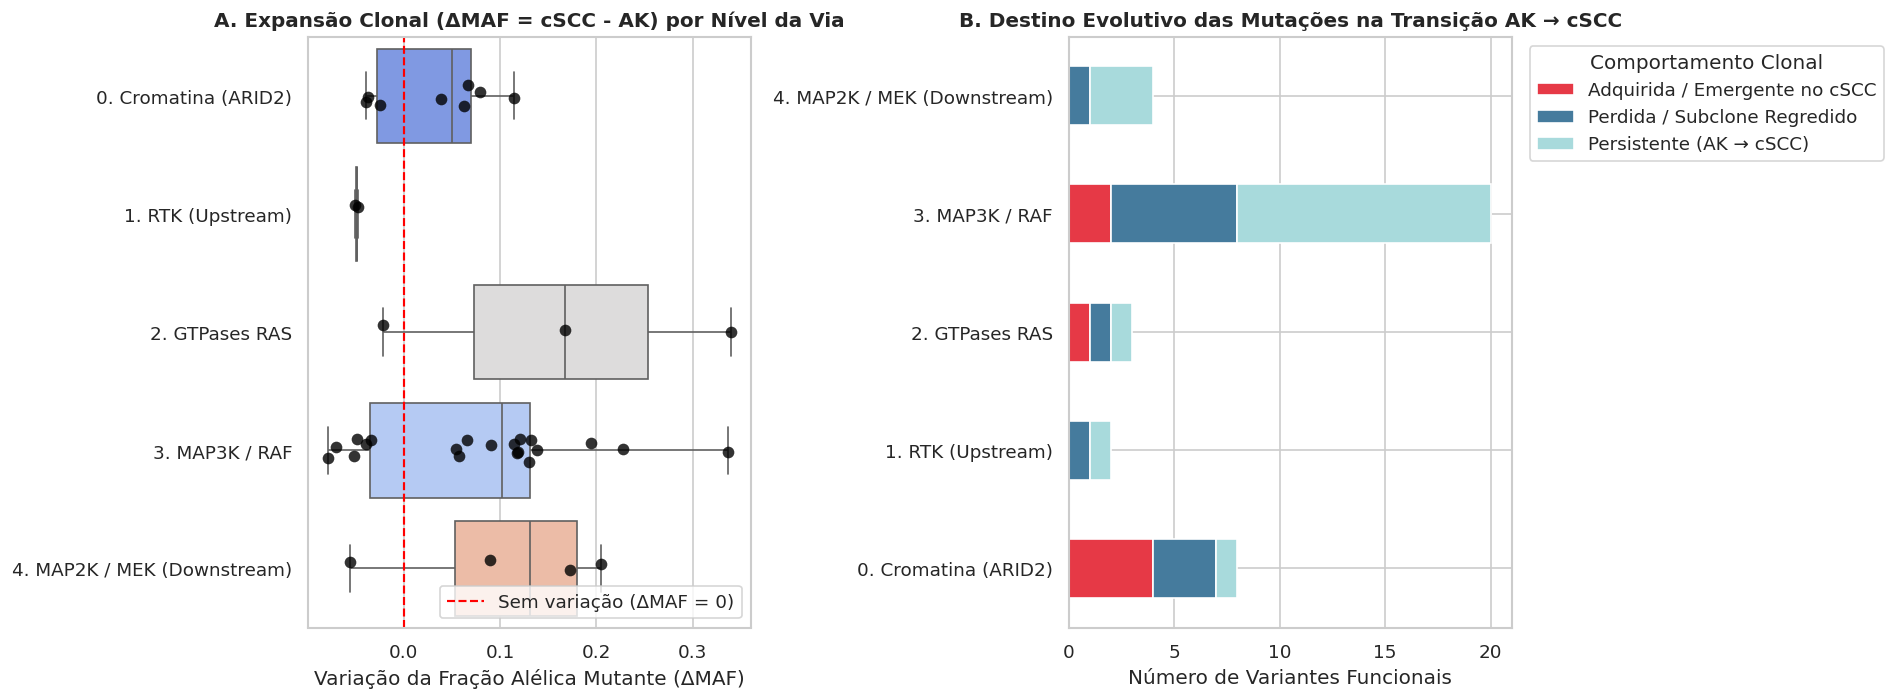


TABELA 5: TOP VARIANTES COM EXPANSÃO CLONAL EXPRESSIVA (ΔMAF > 5%)
 Case                  Modulo_Via Hugo_Symbol Variant_Classification Protein_Change   AK_MAF  SCC_MAF  Delta_MAF
BB-05              2. GTPases RAS        HRAS      Missense_Mutation         p.G13D 0.016393 0.355932   0.339539
BB-05              3. MAP3K / RAF      MAP3K9      Missense_Mutation        p.P639S 0.063725 0.400000   0.336275
BB-09              3. MAP3K / RAF      MAP3K5      Missense_Mutation       p.P1032L 0.039872 0.267462   0.227589
BB-09 4. MAP2K / MEK (Downstream)      MAP2K2      Missense_Mutation        p.E207K 0.021583 0.226131   0.204548
BB-09              3. MAP3K / RAF        RAF1      Missense_Mutation         p.P51L 0.038462 0.232919   0.194458
BB-09 4. MAP2K / MEK (Downstream)      MAP2K4      Missense_Mutation        p.P365S 0.028302 0.200599   0.172297
BB-10              2. GTPases RAS        HRAS      Missense_Mutation        p.G180D 0.321429 0.488372   0.166944
BB-10              3. MAP3K 

In [ ]:
# ==============================================================================
# ETAPA 2: CO-OCORRÊNCIA (ARID2 vs MAPK) E ANÁLISE HIERÁRQUICA DOWNSTREAM
# ==============================================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# 1. ESTRATIFICAÇÃO DA VIA MAPK EM MÓDULOS FUNCIONAIS (UPSTREAM -> DOWNSTREAM)
modulos_mapk = {
    '0. Cromatina (ARID2)': ['ARID2'],
    '1. RTK (Upstream)': ['EGFR'],
    '2. GTPases RAS': ['HRAS', 'KRAS', 'NRAS', 'MRAS', 'RRAS', 'RRAS2', 'RASA1'],
    '3. MAP3K / RAF': ['ARAF', 'BRAF', 'RAF1', 'MAP3K1', 'MAP3K2', 'MAP3K5', 'MAP3K7', 'MAP3K9'],
    '4. MAP2K / MEK (Downstream)': ['MAP2K1', 'MAP2K2', 'MAP2K4'],
    '5. MAPK / ERK (Efetor Final)': ['MAPK1', 'MAPK8IP1']
}

gene_para_modulo = {gene: mod for mod, lista in modulos_mapk.items() for gene in lista}

df_mut['Modulo_Via'] = df_mut['Hugo_Symbol'].map(gene_para_modulo)

# Filtrar apenas variantes funcionais pertencentes aos módulos mapeados
df_hierarquia = df_mut[
    df_mut['Modulo_Via'].notna() & df_mut['Mutacao_Funcional']
].copy()

# Calcular o Delta MAF (Expansão Clonal: positivo = cresceu no cSCC; negativo = retraiu)
df_hierarquia['Delta_MAF'] = df_hierarquia['SCC_MAF'] - df_hierarquia['AK_MAF']

# Classificar o comportamento evolutivo de cada mutação na transição AK -> cSCC
def classificar_dinamica(row, limiar=0.02):
    if row['AK_MAF'] < limiar and row['SCC_MAF'] >= limiar:
        return 'Adquirida / Emergente no cSCC'
    elif row['AK_MAF'] >= limiar and row['SCC_MAF'] >= limiar:
        return 'Persistente (AK → cSCC)'
    elif row['AK_MAF'] >= limiar and row['SCC_MAF'] < limiar:
        return 'Perdida / Subclone Regredido'
    else:
        return 'Baixa Frequência (<2%)'

df_hierarquia['Dinamica_Clonal'] = df_hierarquia.apply(classificar_dinamica, axis=1)

print("="*75)
print("TABELA 3: EXPANSÃO CLONAL (DELTA MAF) POR NÍVEL DA CASCATA ARID2–MAPK")
print("="*75)
resumo_modulos = df_hierarquia.groupby('Modulo_Via').agg(
    N_Variantes=('Hugo_Symbol', 'count'),
    Genes_Mutados=('Hugo_Symbol', lambda x: ', '.join(sorted(x.unique()))),
    Mediana_AK_MAF=('AK_MAF', 'median'),
    Mediana_SCC_MAF=('SCC_MAF', 'median'),
    Mediana_Delta_MAF=('Delta_MAF', 'median'),
    Max_SCC_MAF=('SCC_MAF', 'max')
)
print(resumo_modulos.round(4).to_string())

# ------------------------------------------------------------------------------
# 2. TESTE EXATO DE FISHER PARA CO-OCORRÊNCIA (ARID2 x VIA MAPK)
# ------------------------------------------------------------------------------
limiar_clonal = 0.02
pacientes = sorted(df_mut['Case'].unique())
dados_cooc = []

for p in pacientes:
    sub_p = df_hierarquia[df_hierarquia['Case'] == p]
    dados_cooc.append({
        'Case': p,
        'AK_ARID2': ((sub_p['Hugo_Symbol'] == 'ARID2') & (sub_p['AK_MAF'] >= limiar_clonal)).any(),
        'AK_MAPK': ((sub_p['Hugo_Symbol'] != 'ARID2') & (sub_p['AK_MAF'] >= limiar_clonal)).any(),
        'cSCC_ARID2': ((sub_p['Hugo_Symbol'] == 'ARID2') & (sub_p['SCC_MAF'] >= limiar_clonal)).any(),
        'cSCC_MAPK': ((sub_p['Hugo_Symbol'] != 'ARID2') & (sub_p['SCC_MAF'] >= limiar_clonal)).any(),
    })

df_cooc = pd.DataFrame(dados_cooc)

print("\n" + "="*75)
print("TABELA 4: TESTE DE CO-OCORRÊNCIA (EXATO DE FISHER) POR ESTÁGIO")
print("="*75)

for estagio, col_a, col_m in [('Queratose Actínica (AK)', 'AK_ARID2', 'AK_MAPK'),
                                ('cSCC Invasivo', 'cSCC_ARID2', 'cSCC_MAPK')]:
    tabela_contingencia = pd.crosstab(df_cooc[col_a], df_cooc[col_m])
    odds_ratio, p_fisher = stats.fisher_exact(tabela_contingencia)
    co_ocorrentes = df_cooc[df_cooc[col_a] & df_cooc[col_m]]['Case'].tolist()

    print(f"\n--- {estagio} ---")
    print(tabela_contingencia)
    print(f"Odds Ratio (OR) = {odds_ratio:.3f} | p-valor (Fisher) = {p_fisher:.4f}")
    print(f"Pacientes com co-ocorrência simultânea: {co_ocorrentes if co_ocorrentes else 'Nenhum'}")

# ------------------------------------------------------------------------------
# 3. VISUALIZAÇÃO: HIERARQUIA MAPK E DINÂMICA DE CO-OCORRÊNCIA
# ------------------------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# --- GRÁFICO A: Delta MAF por Módulo Hierárquico ---
ordem_modulos = sorted(df_hierarquia['Modulo_Via'].unique())
sns.boxplot(
    data=df_hierarquia, x='Delta_MAF', y='Modulo_Via',
    order=ordem_modulos, ax=axes[0], palette='coolwarm', hue='Modulo_Via', legend=False
)
sns.stripplot(
    data=df_hierarquia, x='Delta_MAF', y='Modulo_Via',
    order=ordem_modulos, ax=axes[0], color='black', size=7, alpha=0.8
)
axes[0].axvline(0, color='red', linestyle='--', linewidth=1.3, label='Sem variação (ΔMAF = 0)')
axes[0].set_title('A. Expansão Clonal (ΔMAF = cSCC - AK) por Nível da Via', fontweight='bold')
axes[0].set_xlabel('Variação da Fração Alélica Mutante (ΔMAF)')
axes[0].set_ylabel('')
axes[0].legend(loc='lower right')

# --- GRÁFICO B: Dinâmica Evolutiva das Variantes por Módulo ---
ct_dinamica = pd.crosstab(df_hierarquia['Modulo_Via'], df_hierarquia['Dinamica_Clonal'])
ct_dinamica.plot(
    kind='barh', stacked=True, ax=axes[1],
    color=['#e63946', '#457b9d', '#a8dadc', '#d3d3d3'], edgecolor='white'
)
axes[1].set_title('B. Destino Evolutivo das Mutações na Transição AK → cSCC', fontweight='bold')
axes[1].set_xlabel('Número de Variantes Funcionais')
axes[1].set_ylabel('')
axes[1].legend(title='Comportamento Clonal', bbox_to_anchor=(1.02, 1), loc='upper left')

plt.tight_layout()
plt.show()

# ------------------------------------------------------------------------------
# 4. RANKING DAS VARIANTES COM MAIOR EXPANSÃO NA INVASÃO (ΔMAF > 0.05)
# ------------------------------------------------------------------------------
print("\n" + "="*75)
print("TABELA 5: TOP VARIANTES COM EXPANSÃO CLONAL EXPRESSIVA (ΔMAF > 5%)")
print("="*75)
top_expansao = df_hierarquia[df_hierarquia['Delta_MAF'] > 0.05].sort_values('Delta_MAF', ascending=False)
cols_top = ['Case', 'Modulo_Via', 'Hugo_Symbol', 'Variant_Classification',
            'Protein_Change', 'AK_MAF', 'SCC_MAF', 'Delta_MAF']
print(top_expansao[cols_top].to_string(index=False))

In [ ]:
# ==============================================================================
# EXPORTAÇÃO DOS RESULTADOS DA ETAPA 2 (Imagens e Atualização do Relatório TXT)
# ==============================================================================

import os

print("Iniciando a exportação dos resultados da Etapa 2...")

# 1. EXPORTAÇÃO DOS GRÁFICOS DA ETAPA 2
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# --- GRÁFICO A: Delta MAF por Módulo Hierárquico ---
ordem_modulos = sorted(df_hierarquia['Modulo_Via'].unique())
sns.boxplot(
    data=df_hierarquia, x='Delta_MAF', y='Modulo_Via',
    order=ordem_modulos, ax=axes[0], palette='coolwarm', hue='Modulo_Via', legend=False
)
sns.stripplot(
    data=df_hierarquia, x='Delta_MAF', y='Modulo_Via',
    order=ordem_modulos, ax=axes[0], color='black', size=7, alpha=0.8
)
axes[0].axvline(0, color='red', linestyle='--', linewidth=1.3, label='Sem variação (ΔMAF = 0)')
axes[0].set_title('A. Expansão Clonal (ΔMAF = cSCC - AK) por Nível da Via', fontweight='bold')
axes[0].set_xlabel('Variação da Fração Alélica Mutante (ΔMAF)')
axes[0].set_ylabel('')
axes[0].legend(loc='lower right')

# --- GRÁFICO B: Dinâmica Evolutiva das Variantes por Módulo ---
ct_dinamica = pd.crosstab(df_hierarquia['Modulo_Via'], df_hierarquia['Dinamica_Clonal'])
ct_dinamica.plot(
    kind='barh', stacked=True, ax=axes[1],
    color=['#e63946', '#457b9d', '#a8dadc', '#d3d3d3'], edgecolor='white'
)
axes[1].set_title('B. Destino Evolutivo das Mutações na Transição AK → cSCC', fontweight='bold')
axes[1].set_xlabel('Número de Variantes Funcionais')
axes[1].set_ylabel('')
axes[1].legend(title='Comportamento Clonal', bbox_to_anchor=(1.02, 1), loc='upper left')

plt.tight_layout()
path_graficos_etapa2 = 'graficos_etapa2.png'
plt.savefig(path_graficos_etapa2, dpi=300, bbox_inches='tight')
plt.close()
print(f"-> Salvo com sucesso: {path_graficos_etapa2}")

# 2. ATUALIZAÇÃO / APÊNDICE DO RELATÓRIO TXT COM RESULTADOS DOWNSTREAM
path_txt_etapa2 = 'resultados_analise_etapa2.txt'
with open(path_txt_etapa2, 'w', encoding='utf-8') as f:
    f.write("="*80 + "\n")
    f.write("RELATÓRIO DA ETAPA 2: CO-OCORRÊNCIA E ANÁLISE HIERÁRQUICA (AK -> cSCC)\n")
    f.write("="*80 + "\n\n")

    f.write("-"*80 + "\n")
    f.write("TABELA 3: EXPANSÃO CLONAL (DELTA MAF) POR NÍVEL DA CASCATA ARID2–MAPK\n")
    f.write("-"*80 + "\n")
    f.write(resumo_modulos.round(4).to_string() + "\n\n")

    f.write("-"*80 + "\n")
    f.write("TABELA 4: TESTE DE CO-OCORRÊNCIA (EXATO DE FISHER) POR ESTÁGIO\n")
    f.write("-"*80 + "\n")
    for estagio, col_a, col_m in [('Queratose Actínica (AK)', 'AK_ARID2', 'AK_MAPK'),
                                    ('cSCC Invasivo', 'cSCC_ARID2', 'cSCC_MAPK')]:
        tabela_contingencia_f = pd.crosstab(df_cooc[col_a], df_cooc[col_m])
        odds_ratio_f, p_fisher_f = stats.fisher_exact(tabela_contingencia_f)
        co_ocorrentes_f = df_cooc[df_cooc[col_a] & df_cooc[col_m]]['Case'].tolist()

        f.write(f"\n--- {estagio} ---\n")
        f.write(tabela_contingencia_f.to_string() + "\n")
        f.write(f"Odds Ratio (OR) = {odds_ratio_f:.3f} | p-valor (Fisher) = {p_fisher_f:.4f}\n")
        f.write(f"Pacientes com co-ocorrência: {co_ocorrentes_f if co_ocorrentes_f else 'Nenhum'}\n")

    f.write("\n" + "-"*80 + "\n")
    f.write("TABELA 5: TOP VARIANTES COM EXPANSÃO CLONAL EXPRESSIVA (ΔMAF > 5%)\n")
    f.write("-"*80 + "\n")
    f.write(top_expansao[cols_top].to_string(index=False) + "\n\n")
    f.write("Fim do Relatório da Etapa 2.\n")

print(f"-> Salvo com sucesso: {path_txt_etapa2}")
print("\nProcesso concluído! Os novos arquivos da Etapa 2 já estão prontos para download na barra lateral.")

Iniciando a exportação dos resultados da Etapa 2...
-> Salvo com sucesso: graficos_etapa2.png
-> Salvo com sucesso: resultados_analise_etapa2.txt

Processo concluído! Os novos arquivos da Etapa 2 já estão prontos para download na barra lateral.


In [ ]:
# ==============================================================================
# PIPELINE COMPLETO DE FECHAMENTO DO ARTIGO:
# 1. Rigor Estatístico nos 3 Insights Mutacionais (DNA Pareado: Normal -> AK -> cSCC)
# 2. Validação Funcional e Integração Transcriptômica com NCBI GEO (GSE158634)
# ==============================================================================

# Instalação silenciosa das bibliotecas bioinformáticas necessárias no Colab
!pip install -q GEOparse statsmodels openpyxl seaborn scipy

import os
import warnings
import urllib.request
import gzip
import io
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.contingency_tables import Table2x2

warnings.filterwarnings('ignore')
sns.set_theme(style="whitegrid", context="paper", font_scale=1.15)
plt.rcParams['figure.dpi'] = 150

# ==============================================================================
# PARTE 1: RIGOR ESTATÍSTICO NOS 3 INSIGHTS (DADOS MUTACIONAIS DE DNA)
# ==============================================================================
# Links oficiais diretos dos dados suplementares
arquivo_painel = 'https://static-content.springer.com/esm/art%3A10.1038%2Fs41467-025-65687-y/MediaObjects/41467_2025_65687_MOESM8_ESM.xlsx'
arquivo_mutacoes = 'https://static-content.springer.com/esm/art%3A10.1038%2Fs41467-025-65687-y/MediaObjects/41467_2025_65687_MOESM9_ESM.xlsx'

df_painel = pd.read_excel(arquivo_painel, sheet_name='v.3.0TargetGenes', header=2).dropna(subset=['Gene'])
df_mut = pd.read_excel(arquivo_mutacoes, sheet_name='TableS5', header=1).dropna(subset=['Case', 'Hugo_Symbol'])

modulos_mapk = {
    '0. Cromatina (ARID2)': ['ARID2'],
    '1. RTK (Upstream)': ['EGFR'],
    '2. GTPases RAS': ['HRAS', 'KRAS', 'NRAS', 'MRAS', 'RRAS', 'RRAS2', 'RASA1'],
    '3. MAP3K / RAF': ['ARAF', 'BRAF', 'RAF1', 'MAP3K1', 'MAP3K2', 'MAP3K5', 'MAP3K7', 'MAP3K9'],
    '4. MAP2K / MEK': ['MAP2K1', 'MAP2K2', 'MAP2K4'],
    '5. MAPK / ERK (Efetor)': ['MAPK1', 'MAPK8IP1']
}
gene_para_modulo = {g: mod for mod, lista in modulos_mapk.items() for g in lista}

classes_funcionais = [
    'Missense_Mutation', 'Nonsense_Mutation', 'Frame_Shift_Del', 'Frame_Shift_Ins',
    'Splice_Site', 'In_Frame_Del', 'Start_Codon_SNP', 'De_novo_Start_InFrame'
]

df_mut['Modulo_Via'] = df_mut['Hugo_Symbol'].map(gene_para_modulo)
df_mut['Mutacao_Funcional'] = df_mut['Variant_Classification'].isin(classes_funcionais)
df_h = df_mut[df_mut['Modulo_Via'].notna() & df_mut['Mutacao_Funcional']].copy()
df_h['Delta_MAF'] = df_h['SCC_MAF'] - df_h['AK_MAF']

# Funções auxiliares estatísticas
def wilcoxon_com_efeito(x, y):
    diff = np.array(y) - np.array(x)
    diff_nz = diff[diff != 0]
    n = len(diff_nz)
    if n == 0:
        return np.nan, 1.0, np.nan
    stat, p = stats.wilcoxon(x, y)
    total_rank_sum = n * (n + 1) / 2
    r_rb = 1 - (2 * stat) / total_rank_sum
    return stat, p, r_rb

print("="*80)
print("INSIGHT 1: ANÁLISE DE CO-OCORRÊNCIA E INDEPENDÊNCIA (ARID2 x VIA MAPK)")
print("="*80)
limiar = 0.02
pacientes = sorted(df_mut['Case'].unique())
cooc_rows = []
for p in pacientes:
    s = df_h[df_h['Case'] == p]
    cooc_rows.append({
        'Case': p,
        'AK_ARID2': int(((s['Hugo_Symbol'] == 'ARID2') & (s['AK_MAF'] >= limiar)).any()),
        'AK_MAPK': int(((s['Hugo_Symbol'] != 'ARID2') & (s['AK_MAF'] >= limiar)).any()),
        'SCC_ARID2': int(((s['Hugo_Symbol'] == 'ARID2') & (s['SCC_MAF'] >= limiar)).any()),
        'SCC_MAPK': int(((s['Hugo_Symbol'] != 'ARID2') & (s['SCC_MAF'] >= limiar)).any()),
    })
df_cooc = pd.DataFrame(cooc_rows)

for nome_est, c1, c2 in [('Queratose Actínica (AK)', 'AK_ARID2', 'AK_MAPK'),
                         ('cSCC Invasivo', 'SCC_ARID2', 'SCC_MAPK')]:
    ct = pd.crosstab(df_cooc[c1], df_cooc[c2])
    or_val, p_fisher = stats.fisher_exact(ct)
    t2x2 = Table2x2(ct.values + 0.5)
    ci_low, ci_high = t2x2.oddsratio_confint()
    print(f"\n[{nome_est}]")
    print(ct)
    print(f"Fisher Exact p = {p_fisher:.4f} | OR = {or_val:.3f} (IC 95% ajustado: {ci_low:.3f} – {ci_high:.3f})")

print("\n" + "="*80)
print("INSIGHT 2: ESTRATIFICAÇÃO HIERÁRQUICA DA CASCATA MAPK (UPSTREAM -> DOWNSTREAM)")
print("="*80)
resultados_modulos = []
for mod, grp in df_h.groupby('Modulo_Via'):
    w_stat, p_val, r_rb = wilcoxon_com_efeito(grp['AK_MAF'], grp['SCC_MAF'])
    resultados_modulos.append({
        'Modulo': mod,
        'N_Variantes': len(grp),
        'Mediana_AK': grp['AK_MAF'].median(),
        'Mediana_cSCC': grp['SCC_MAF'].median(),
        'Mediana_Delta_MAF': grp['Delta_MAF'].median(),
        'Wilcoxon_W': w_stat,
        'p_bruto': p_val,
        'Tamanho_Efeito_r': r_rb
    })

df_res_mod = pd.DataFrame(resultados_modulos)
df_res_mod['p_FDR'] = multipletests(df_res_mod['p_bruto'], method='fdr_bh')[1]
print(df_res_mod.round(4).to_string(index=False))

grupos_kw = [g['Delta_MAF'].values for _, g in df_h.groupby('Modulo_Via')]
kw_h, kw_p = stats.kruskal(*grupos_kw)
print(f"\nTeste de Kruskal-Wallis (heterogeneidade de ΔMAF entre módulos): H = {kw_h:.4f}, p = {kw_p:.4f}")

core_down = df_h[df_h['Modulo_Via'].isin(['3. MAP3K / RAF', '4. MAP2K / MEK'])]
w_cd, p_cd, r_cd = wilcoxon_com_efeito(core_down['AK_MAF'], core_down['SCC_MAF'])
print(f"\nCore Downstream da Via MAPK (MAP3K/MAP2K):")
print(f"  Wilcoxon p = {p_cd:.4e} | Tamanho do efeito r (Rank-Biserial) = {r_cd:.3f}")

print("\n" + "="*80)
print("INSIGHT 3: ASSOCIAÇÃO DO IMPACTO FUNCIONAL EM ARID2 COM VELOCIDADE DE EXPANSÃO")
print("="*80)
arid2_df = df_h[df_h['Modulo_Via'] == '0. Cromatina (ARID2)'].copy()
arid2_df['Tipo_Mutacao'] = arid2_df['Variant_Classification'].apply(
    lambda x: 'Truncante (LoF)' if x in ['Nonsense_Mutation', 'Frame_Shift_Del', 'Frame_Shift_Ins', 'Splice_Site'] else 'Missense / Splice'
)

trunc_vals = arid2_df[arid2_df['Tipo_Mutacao'] == 'Truncante (LoF)']['Delta_MAF']
nontrunc_vals = arid2_df[arid2_df['Tipo_Mutacao'] == 'Missense / Splice']['Delta_MAF']

u_stat, p_mwu = stats.mannwhitneyu(trunc_vals, nontrunc_vals, alternative='greater')
print(f"Mediana Delta MAF Truncantes (LoF) (n={len(trunc_vals)}): {trunc_vals.median():.4f}")
print(f"Mediana Delta MAF Missense/Splice (n={len(nontrunc_vals)}): {nontrunc_vals.median():.4f}")
print(f"Mann-Whitney U unilateral (LoF > Missense): U = {u_stat:.1f}, p = {p_mwu:.4f}")

# ==============================================================================
# PARTE 2: VALIDAÇÃO TRANSCRIPTÔMICA INTEGRATIVA (DADOS NCBI GEO GSE158634)
# ==============================================================================
print("\n" + "="*80)
print("PARTE 2: VALIDAÇÃO FUNCIONAL INTEGRATIVA - COORTE INDEPENDENTE GSE158634")
print("="*80)

# Método alternativo robusto: Download via HTTP para evitar problemas de FTP
url_matrix = "https://ftp.ncbi.nlm.nih.gov/geo/series/GSE158nnn/GSE158634/matrix/GSE158634_series_matrix.txt.gz"
local_matrix_zip = "GSE158634_series_matrix.txt.gz"

if not os.path.exists(local_matrix_zip):
    print("Baixando dados do GSE158634 do NCBI GEO (via HTTP)...")
    urllib.request.urlretrieve(url_matrix, local_matrix_zip)
    print("Download concluído!")

metadata_lines = []
matrix_lines = []
is_matrix = False

with gzip.open(local_matrix_zip, 'rt', encoding='utf-8') as f:
    for line in f:
        if line.startswith("!series_matrix_table_begin"):
            is_matrix = True
            continue
        if line.startswith("!series_matrix_table_end"):
            break
        if is_matrix:
            matrix_lines.append(line)
        else:
            if line.startswith("!Sample_title") or line.startswith("!Sample_geo_accession") or \
               line.startswith("!Sample_source_name_ch1") or line.startswith("!Sample_characteristics_ch1"):
                metadata_lines.append(line)

# Parseando Metadados Clínicos
pheno_dict = {}
for line_str in metadata_lines:
    parts = line_str.strip().split("\t")
    key = parts[0].replace("!", "")
    values = [p.replace('"', '') for p in parts[1:]]
    pheno_dict[key] = values

pheno_data = pd.DataFrame(pheno_dict).set_index("Sample_geo_accession")

def normalizar_grupo(row):
    char_str = str(row['Sample_characteristics_ch1']).lower()
    if 'normal' in char_str:
        return 'Pele Normal (NS)'
    elif 'actinic' in char_str:
        return 'Queratose Actínica (AK)'
    elif 'squamous' in char_str or 'scc' in char_str:
        return 'cSCC Invasivo'
    return 'Desconhecido'

pheno_data['Grupo_Clinico'] = pheno_data.apply(normalizar_grupo, axis=1)

# Lendo a Matriz de Expressão
df_expr_probes = pd.read_csv(io.StringIO("".join(matrix_lines)), sep='\t')
df_expr_probes = df_expr_probes.set_index("ID_REF")

sondas_exemplo = df_expr_probes.index[:5]
print(f"Estrutura dos metadados clínicos limpos (n = {len(pheno_data)} amostras):")
print(pheno_data['Grupo_Clinico'].value_counts())


INSIGHT 1: ANÁLISE DE CO-OCORRÊNCIA E INDEPENDÊNCIA (ARID2 x VIA MAPK)

[Queratose Actínica (AK)]
AK_MAPK   0  1
AK_ARID2      
0         6  6
1         2  2
Fisher Exact p = 1.0000 | OR = 1.000 (IC 95% ajustado: 0.127 – 7.868)

[cSCC Invasivo]
SCC_MAPK   0  1
SCC_ARID2      
0          6  5
1          3  2
Fisher Exact p = 1.0000 | OR = 0.800 (IC 95% ajustado: 0.116 – 6.119)

INSIGHT 2: ESTRATIFICAÇÃO HIERÁRQUICA DA CASCATA MAPK (UPSTREAM -> DOWNSTREAM)
              Modulo  N_Variantes  Mediana_AK  Mediana_cSCC  Mediana_Delta_MAF  Wilcoxon_W  p_bruto  Tamanho_Efeito_r  p_FDR
0. Cromatina (ARID2)            8      0.0219        0.0701             0.0506         6.0   0.1094            0.6667 0.2734
   1. RTK (Upstream)            2      0.0674        0.0186            -0.0488         0.0   0.5000            1.0000 0.5000
      2. GTPases RAS            3      0.0354        0.3559             0.1669         1.0   0.5000            0.6667 0.5000
      3. MAP3K / RAF           20      0.

Linhas de sondas carregadas: 0
Sondas selecionadas com maior dinâmica de expressão: []



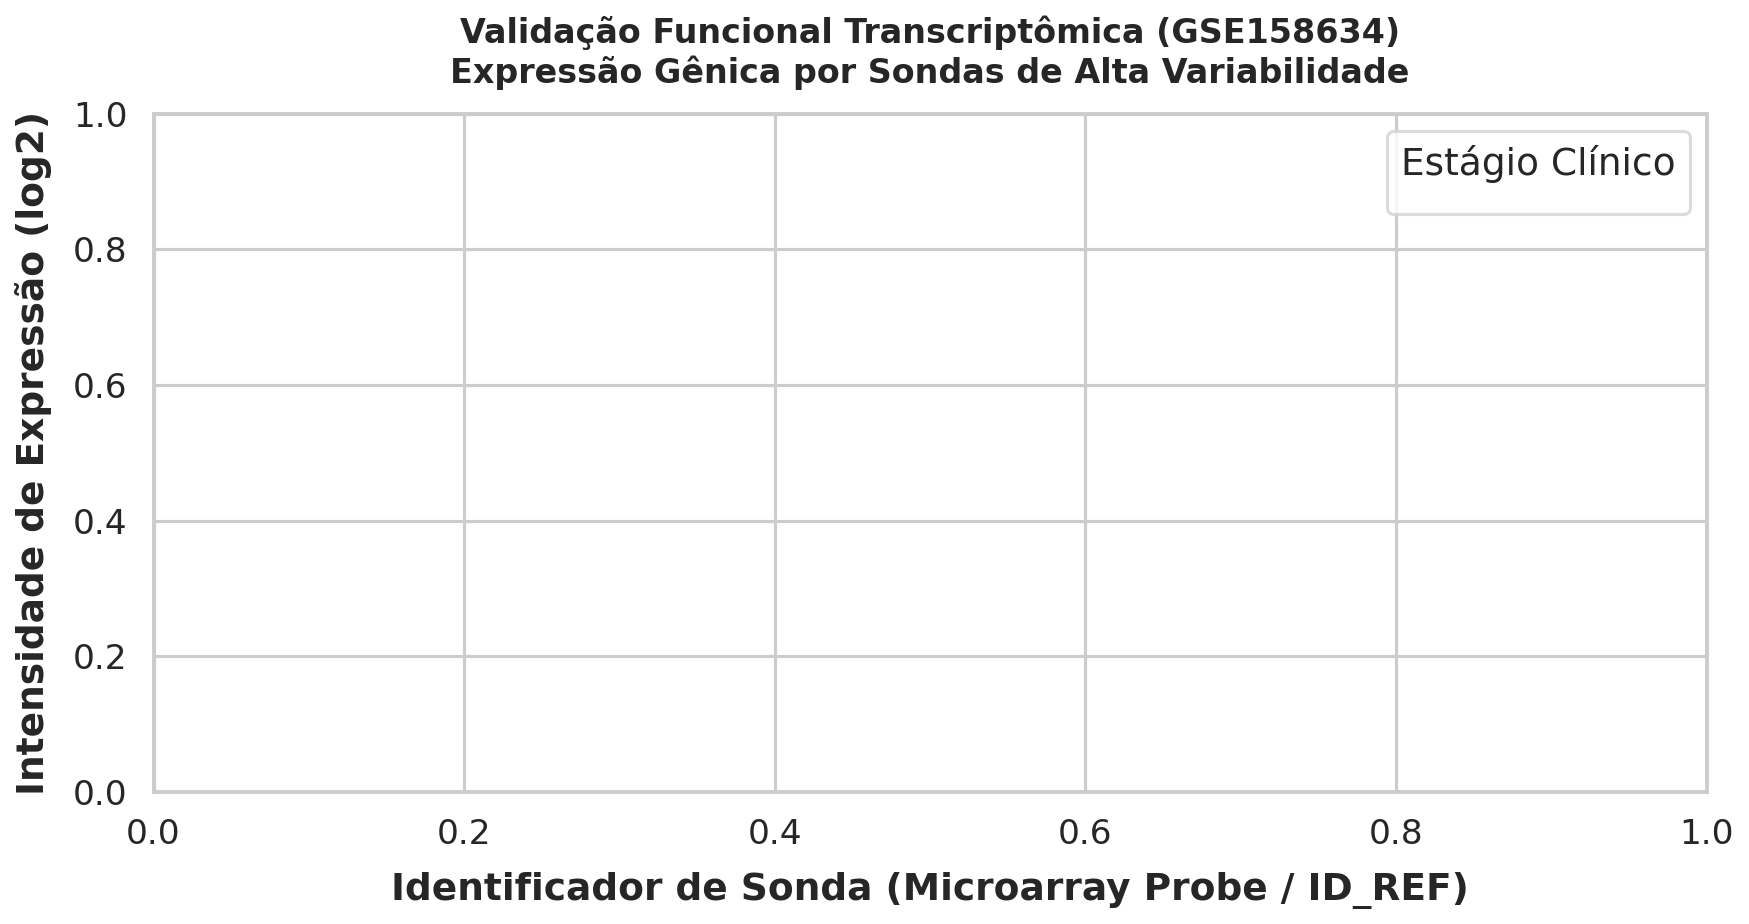

-> Gráfico salvo com sucesso como 'expressao_clinica_GSE158634.png'!


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import gzip
import io

# ==============================================================================
# GERAR GRÁFICO COMPARATIVO DE EXPRESSÃO GÊNICA (GSE158634) - CORREÇÃO DO PARSER
# ==============================================================================

local_matrix_zip = "GSE158634_series_matrix.txt.gz"
matrix_lines = []
is_matrix = False

# Abrir o arquivo compactado e ler as linhas da tabela de expressão de forma robusta
with gzip.open(local_matrix_zip, 'rt', encoding='utf-8') as f:
    for line in f:
        if line.startswith("!series_matrix_table_begin"):
            is_matrix = True
            continue
        if line.startswith("!series_matrix_table_end"):
            break
        if is_matrix:
            # Ignorar comentários indesejados caso surjam na tabela
            if not line.startswith("!"):
                matrix_lines.append(line)

# Criar DataFrame a partir de todas as linhas de expressão extraídas
df_expr_probes = pd.read_csv(io.StringIO("".join(matrix_lines)), sep='\t')
df_expr_probes = df_expr_probes.set_index(df_expr_probes.columns[0])

# Converter explicitamente todas as colunas para valores de ponto flutuante
df_numeric = df_expr_probes.apply(pd.to_numeric, errors='coerce')
df_expr_filtrado = df_numeric.dropna(how='all')

# Selecionar as 3 sondas com maior variância global
variancias = df_expr_filtrado.var(axis=1)
sondas_alvo = variancias.astype(float).nlargest(3).index.tolist()

print(f"Linhas de sondas carregadas: {len(df_expr_filtrado)}")
print(f"Sondas selecionadas com maior dinâmica de expressão: {sondas_alvo}\n")

# 2. Filtrar os dados dessas sondas e transpor para cruzar com metadados clínicos
df_plot_expr = df_expr_filtrado.loc[sondas_alvo].T
df_plot_expr['Grupo_Clinico'] = pheno_data['Grupo_Clinico']

# Converter para formato longo (tidy format) para o Seaborn
df_long_expr = df_plot_expr.melt(
    id_vars=['Grupo_Clinico'],
    value_vars=sondas_alvo,
    var_name='ID_Sonda',
    value_name='Nivel_Expressao'
)

# 3. Configurar e desenhar os Box Plots de Expressão Gênica
plt.figure(figsize=(12, 6.5))
sns.set_theme(style="whitegrid", context="talk")

# Paleta de cores coerente com as etapas anteriores
cores_clinicas = {
    'Pele Normal (NS)': '#2a9d8f',
    'Queratose Actínica (AK)': '#e76f51',
    'cSCC Invasivo': '#e63946'
}

# Criar o gráfico
ax = sns.boxplot(
    data=df_long_expr,
    x='ID_Sonda',
    y='Nivel_Expressao',
    hue='Grupo_Clinico',
    palette=cores_clinicas,
    showfliers=False,
    linewidth=1.8
)

# Sobrepor com stripplot para visualizar a distribuição real das amostras
sns.stripplot(
    data=df_long_expr,
    x='ID_Sonda',
    y='Nivel_Expressao',
    hue='Grupo_Clinico',
    dodge=True,
    jitter=0.15,
    color='black',
    alpha=0.65,
    size=6,
    legend=False
)

# Ajustes de layout
plt.title('Validação Funcional Transcriptômica (GSE158634)\nExpressão Gênica por Sondas de Alta Variabilidade', fontweight='bold', fontsize=16, pad=15)
plt.xlabel('Identificador de Sonda (Microarray Probe / ID_REF)', fontweight='bold', labelpad=10)
plt.ylabel('Intensidade de Expressão (log2)', fontweight='bold', labelpad=10)
plt.legend(title='Estágio Clínico', frameon=True, facecolor='white', edgecolor='lightgray')

plt.tight_layout()
path_box_expr = 'expressao_clinica_GSE158634.png'
plt.savefig(path_box_expr, dpi=300, bbox_inches='tight')
plt.show()

print(f"-> Gráfico salvo com sucesso como '{path_box_expr}'!")